# NyahMuk: data cleaning (Stagnant Water + VisText-Mosquito)
Run the cells top to bottom. Nothing in your original zips is changed. Cleaned data goes to `/content/clean` and is zipped back to Drive at the end.

## Step 0. Mount Drive and set paths

In [2]:
import os, re, ast, shutil, zipfile, hashlib, random, json, collections
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab

# ---- EDIT THESE TWO PATHS to where you uploaded the zips ----
ZIP_SW = Path('/content/drive/MyDrive/NyahMuk/Stagnant_Water_and_Wet_Surface_Dataset-fJZUTl.zip')
ZIP_VT = Path('/content/drive/MyDrive/NyahMuk/VisText-Mosquito_A_Multimodal_Dataset_for_Mosquito.zip')
DRIVE_OUT = Path('/content/drive/MyDrive/NyahMuk/clean_output')

WORK = Path('/content/work')      # extracted raw data (fast local disk)
OUT  = Path('/content/clean')     # cleaned datasets + reports

# ---- Cleaning settings (safe defaults) ----
SEED = 42
HASH_THR = 6          # VisText: dHash difference (out of 64 bits) that counts as "same image" (flip-aware)
SW_HASH_THR = 3       # Stagnant Water: stricter, because its small 256x256 road photos look alike
MIN_BOX_PX = 3        # drop boxes narrower/shorter than this many pixels
EXCLUDE_EMPTY = True  # move images with no valid labels to review/ instead of training on them
TRAIN_KEEP_AUG = True # VisText train: keep augmented near-copies (valid/test always keep one per group)
SW_ID_BLOCK = 10      # Stagnant Water: consecutive image IDs (burst shots) in blocks of this size stay in one split
SW_SPLIT = (0.8, 0.1, 0.1)
random.seed(SEED); np.random.seed(SEED)

Mounted at /content/drive


In [3]:
import os
print(os.listdir('/content/drive/MyDrive/NyahMuk'))

['VisText-Mosquito_A_Multimodal_Dataset_for_Mosquito.zip', 'Stagnant_Water_and_Wet_Surface_Dataset-fJZUTl.zip', 'clean_output', 'audit_reports']


## Step 1. Copy zips to local disk and unzip (handles the zip-inside-zip in VisText)

In [ ]:
def unzip(zip_path, dest):
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    for inner in list(dest.rglob('*.zip')):          # nested zips
        unzip(inner, inner.with_suffix(''))

if WORK.exists(): shutil.rmtree(WORK)
for name, zp in [('sw', ZIP_SW), ('vt', ZIP_VT)]:
    local = WORK / f'{name}.zip'
    local.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(zp, local)
    unzip(local, WORK / name)
    local.unlink()

# locate dataset roots
SW_ROOT = next((WORK/'sw').rglob('classes.txt')).parent
VT_CSV  = next((WORK/'vt').rglob('image_discription.csv'))
DET_ROOT = SEG_ROOT = None
for y in (WORK/'vt').rglob('data.yaml'):
    nc = int(re.search(r'nc:\s*(\d+)', y.read_text()).group(1))
    if nc == 5: DET_ROOT = y.parent
    if nc == 2: SEG_ROOT = y.parent
print('Stagnant Water :', SW_ROOT)
print('VisText detect :', DET_ROOT)
print('VisText segment:', SEG_ROOT)
assert SW_ROOT and DET_ROOT and SEG_ROOT

Stagnant Water : /content/work/sw/Stagnant Water and Wet Surface Dataset
VisText detect : /content/work/vt/VisText-Mosquito A Multimodal Dataset for Mosquito/Breeding Place Detection/Breeding Place Detection
VisText segment: /content/work/vt/VisText-Mosquito A Multimodal Dataset for Mosquito/Water Surface Segmentation/Water Surface Segmentation


## Step 2. Helper functions (inventory, hashing, label cleaning, clustering)

In [ ]:
def md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def dhash(im, n=8):
    g = im.convert('L').resize((n + 1, n), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def find_label(img):
    if img.parent.name == 'images':
        return img.parent.parent / 'labels' / (img.stem + '.txt')
    return img.with_suffix('.txt')

def read_labels(p):
    rows = []
    if p is None or not Path(p).exists(): return rows
    for ln in Path(p).read_text().splitlines():
        t = ln.split()
        if not t: continue
        try: rows.append((int(float(t[0])), [float(x) for x in t[1:]]))
        except ValueError: rows.append((-1, []))
    return rows

def poly_to_box(v):
    xs, ys = v[0::2], v[1::2]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    return [(x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0]

def clean_labels(rows, kind, w, h, ncls):
    """kind='box' -> YOLO boxes (polygons converted); kind='poly' -> polygons kept."""
    out, st = [], collections.Counter()
    for c, v in rows:
        if c < 0 or c >= ncls: st['bad_class_or_line'] += 1; continue
        if kind == 'box':
            if len(v) != 4:
                if len(v) >= 6 and len(v) % 2 == 0: v = poly_to_box(v); st['poly_to_box'] += 1
                else: st['bad_line'] += 1; continue
            cx, cy, bw, bh = v
            x0, x1 = cx - bw / 2, cx + bw / 2
            y0, y1 = cy - bh / 2, cy + bh / 2
            if min(x0, y0) < -1e-4 or max(x1, y1) > 1 + 1e-4: st['clipped'] += 1
            x0, x1, y0, y1 = max(x0, 0), min(x1, 1), max(y0, 0), min(y1, 1)
            bw, bh = x1 - x0, y1 - y0
            if bw * w < MIN_BOX_PX or bh * h < MIN_BOX_PX: st['tiny_dropped'] += 1; continue
            out.append((c, [(x0 + x1) / 2, (y0 + y1) / 2, bw, bh]))
        else:
            if len(v) < 6 or len(v) % 2: st['bad_line'] += 1; continue
            vv = [min(max(x, 0), 1) for x in v]
            if any(abs(a - b) > 1e-4 for a, b in zip(v, vv)): st['clipped'] += 1
            out.append((c, vv))
    return out, st

def inventory(root, skip=()):
    """One row per image: paths, split, size, md5, perceptual hashes. Also lists orphan labels."""
    rows, used = [], set()
    for p in sorted(root.rglob('*')):
        if p.suffix.lower() not in {'.jpg', '.jpeg', '.png'}: continue
        if any(s in p.parts for s in skip): continue
        rel = p.relative_to(root)
        split = rel.parts[0] if rel.parts[0] in ('train', 'valid', 'test') else 'unsplit'
        lp = find_label(p)
        has_lbl = lp.exists()
        if has_lbl: used.add(lp)
        rec = dict(img=p, lbl=lp if has_lbl else None, split=split, rel=str(rel), corrupt=False)
        try:
            with Image.open(p) as im:
                im.load()
                rec.update(w=im.size[0], h=im.size[1], h1=dhash(im), h2=dhash(ImageOps.mirror(im)))
            rec['md5'] = md5(p)
        except Exception:
            rec.update(corrupt=True, w=0, h=0, md5='', h1=None, h2=None)
        rows.append(rec)
    orphans = [p for p in root.rglob('*.txt')
               if p.name not in ('classes.txt',) and 'README' not in p.name
               and not any(s in p.parts for s in skip) and p not in used]
    return pd.DataFrame(rows), orphans

def cluster(df, thr, extra_key=None):
    """Union-find: same md5, same perceptual image (also mirrored), or same extra_key."""
    n = len(df); parent = list(range(n))
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb: parent[rb] = ra
    for idx in df.groupby('md5').indices.values():
        for i in idx[1:]: union(idx[0], i)
    if extra_key is not None:
        for k, idx in pd.Series(extra_key).groupby(extra_key).indices.items():
            if k is None or (isinstance(k, float) and np.isnan(k)): continue
            for i in idx[1:]: union(idx[0], i)
    H1 = np.stack(df.h1.values); H2 = np.stack(df.h2.values)
    for s in range(0, n, 100):
        a = H1[s:s + 100, None, :]
        d = np.minimum((a != H1[None]).sum(-1), (a != H2[None]).sum(-1))
        ii, jj = np.where(d <= thr)
        for i, j in zip(ii + s, jj):
            if i < j: union(i, j)
    return np.array([find(i) for i in range(n)])

## Step 3. Core cleaning pipeline
For each dataset: check pairs and corruption, clean labels, remove byte-identical duplicates, group near-duplicates, fix split leakage, write clean files.

In [ ]:
def process(ds, root, kind, names, mode, skip=(), id_block=None, thr=HASH_THR):
    ncls = len(names)
    log = []                                   # every decision, one line per image
    inv, orphans = inventory(root, skip)
    print(f'[{ds}] images found: {len(inv)} | orphan label files: {len(orphans)}')
    for o in orphans: log.append(dict(img=str(o.relative_to(root)), action='dropped', reason='label_without_image'))

    # 1. corrupt or unlabeled images
    for _, r in inv[inv.corrupt].iterrows(): log.append(dict(img=r.rel, action='dropped', reason='corrupt_image'))
    for _, r in inv[(~inv.corrupt) & inv.lbl.isna()].iterrows(): log.append(dict(img=r.rel, action='dropped', reason='image_without_label'))
    inv = inv[(~inv.corrupt) & inv.lbl.notna()].reset_index(drop=True)

    # 2. clean labels
    cleaned, stats = [], collections.Counter()
    for _, r in inv.iterrows():
        c, st = clean_labels(read_labels(r.lbl), kind, r.w, r.h, ncls)
        cleaned.append(c); stats.update(st)
    inv['rows'] = cleaned
    inv['n_ann'] = inv.rows.map(len)
    print(f'[{ds}] label fixes:', dict(stats))

    # 3. images with no valid annotations -> review folder
    if EXCLUDE_EMPTY:
        for _, r in inv[inv.n_ann == 0].iterrows(): log.append(dict(img=r.rel, action='review', reason='no_valid_annotations'))
        review = inv[inv.n_ann == 0].copy()
        inv = inv[inv.n_ann > 0].reset_index(drop=True)
    else:
        review = inv.iloc[0:0].copy()

    # 4. exact duplicates: keep the best-annotated copy (most annotations)
    inv['pref'] = inv.rel.str.contains('wet surface', case=False).astype(int) if mode == 'random' else 0
    inv = inv.sort_values(['md5', 'n_ann', 'pref'], ascending=[True, False, False]).reset_index(drop=True)
    conflicts = []
    for m, g in inv.groupby('md5'):
        if len(g) > 1:
            sigs = {tuple(sorted((c, round(v[0], 3)) for c, v in r.rows)) for _, r in g.iterrows()}
            conflicts.append(dict(md5=m, kept=g.iloc[0].rel, dropped=' | '.join(g.iloc[1:].rel), n_copies=len(g), labels_differ=len(sigs) > 1))
    dup_idx = inv.index[inv.duplicated('md5', keep='first')]
    for i in dup_idx: log.append(dict(img=inv.loc[i, 'rel'], action='dropped', reason='exact_duplicate'))
    inv = inv.drop(dup_idx).reset_index(drop=True)
    print(f'[{ds}] exact duplicate copies removed: {len(dup_idx)} | groups where labels disagreed: {sum(c["labels_differ"] for c in conflicts)}')

    # 5. near-duplicate groups (also mirrored) + optional ID blocks
    extra = None
    if id_block:
        ids = inv.img.map(lambda p: int(re.match(r'image(\d+)', p.stem).group(1)) // id_block if re.match(r'image(\d+)', p.stem) else None)
        extra = ids.astype(object).where(ids.notna(), None).tolist()
    inv['grp'] = cluster(inv, thr, extra)
    print(f'[{ds}] images: {len(inv)} -> groups: {inv.grp.nunique()} (largest group = {inv.grp.value_counts().max()})')

    # 6. final split
    if mode == 'random':
        grps = inv.grp.unique().tolist(); random.Random(SEED).shuffle(grps)
        sizes = inv.groupby('grp').size()
        target = {'train': SW_SPLIT[0], 'valid': SW_SPLIT[1], 'test': SW_SPLIT[2]}
        total = len(inv); cnt = collections.Counter(); gsplit = {}
        for g in grps:
            s = max(target, key=lambda k: target[k] - cnt[k] / total)   # fill the most under-filled split
            gsplit[g] = s; cnt[s] += sizes[g]
        inv['final'] = inv.grp.map(gsplit)
    else:
        prio = {'test': 2, 'valid': 1, 'train': 0}
        gsplit = inv.groupby('grp').split.agg(lambda s: max(s, key=prio.get))
        leaked = inv.groupby('grp').split.nunique()
        print(f'[{ds}] groups spanning several splits (true leakage): {(leaked > 1).sum()}')
        inv['final'] = inv.grp.map(gsplit)
        inv['was_leak'] = inv.grp.map(leaked > 1)
        for _, r in inv[inv.split != inv.final].iterrows(): log.append(dict(img=r.rel, action='dropped', reason=f'leakage_copy_in_{r.split}_(group_kept_in_{r.final})'))
        inv = inv[inv.split == inv.final]
        # eval splits: one image per group; train: keep augmented copies if TRAIN_KEEP_AUG
        inv = inv.sort_values(['grp', 'n_ann'], ascending=[True, False])
        keep_one = (inv.final != 'train') | (not TRAIN_KEEP_AUG)
        extra_idx = inv.index[inv.duplicated('grp', keep='first') & keep_one]
        for i in extra_idx: log.append(dict(img=inv.loc[i, 'rel'], action='dropped', reason='near_duplicate_in_' + inv.loc[i, 'final']))
        inv = inv.drop(extra_idx)

    # 7. write output
    base = OUT / ds
    if base.exists(): shutil.rmtree(base)
    meta = []
    for _, r in inv.iterrows():
        new = f'{r.img.stem}__{r.md5[:6]}'
        di, dl = base / r.final / 'images', base / r.final / 'labels'
        di.mkdir(parents=True, exist_ok=True); dl.mkdir(parents=True, exist_ok=True)
        shutil.copy(r.img, di / (new + r.img.suffix.lower()))
        (dl / (new + '.txt')).write_text('\n'.join(f"{c} " + ' '.join(f'{x:.6f}' for x in v) for c, v in r.rows) + '\n')
        meta.append(dict(new_name=new, original=r.rel, split=r.final, group=int(r.grp), n_ann=r.n_ann))
        log.append(dict(img=r.rel, action='kept', reason=f'-> {r.final}'))
    for _, r in review.iterrows():
        d = OUT / 'review' / ds; d.mkdir(parents=True, exist_ok=True)
        shutil.copy(r.img, d / (r.img.stem + '__' + r.md5[:6] + r.img.suffix.lower()))
    (base / 'data.yaml').write_text(
        f"path: {base}\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: {ncls}\nnames: {names}\n")
    (OUT / 'reports').mkdir(parents=True, exist_ok=True)
    pd.DataFrame(log).to_csv(OUT / 'reports' / f'{ds}_decisions.csv', index=False)
    pd.DataFrame(meta).to_csv(OUT / 'reports' / f'{ds}_files.csv', index=False)
    if conflicts: pd.DataFrame(conflicts).to_csv(OUT / 'reports' / f'{ds}_duplicate_conflicts.csv', index=False)
    print(f'[{ds}] kept per split:', inv.final.value_counts().to_dict(), '| sent to review:', len(review))
    return inv, pd.DataFrame(log)

def yaml_names(root):
    return ast.literal_eval(re.search(r'names:\s*(\[.*?\])', (root / 'data.yaml').read_text()).group(1))

if OUT.exists(): shutil.rmtree(OUT)
SW_NAMES = [l.strip() for l in (SW_ROOT / 'classes.txt').read_text().splitlines() if l.strip()]

## Step 4. Run cleaning on each dataset

In [ ]:
sw_inv,  sw_log  = process('stagnant_water', SW_ROOT,  'box',  SW_NAMES,           'random', skip=('Raw data',), id_block=SW_ID_BLOCK, thr=SW_HASH_THR)
det_inv, det_log = process('vistext_det',   DET_ROOT, 'box',  yaml_names(DET_ROOT), 'given')
seg_inv, seg_log = process('vistext_seg',   SEG_ROOT, 'poly', yaml_names(SEG_ROOT), 'given')

[stagnant_water] images found: 1976 | orphan label files: 1
[stagnant_water] label fixes: {'tiny_dropped': 12}
[stagnant_water] exact duplicate copies removed: 167 | groups where labels disagreed: 166
[stagnant_water] images: 1807 -> groups: 200 (largest group = 60)
[stagnant_water] kept per split: {'train': 1445, 'valid': 182, 'test': 180} | sent to review: 1
[vistext_det] images found: 4425 | orphan label files: 0
[vistext_det] label fixes: {'poly_to_box': 161, 'tiny_dropped': 6}
[vistext_det] exact duplicate copies removed: 52 | groups where labels disagreed: 0
[vistext_det] images: 4335 -> groups: 1799 (largest group = 9)
[vistext_det] groups spanning several splits (true leakage): 19
[vistext_det] kept per split: {'train': 3714, 'valid': 369, 'test': 182} | sent to review: 38
[vistext_seg] images found: 331 | orphan label files: 0
[vistext_seg] label fixes: {}
[vistext_seg] exact duplicate copies removed: 4 | groups where labels disagreed: 3
[vistext_seg] images: 324 -> groups: 12

## Step 5. Independent re-check of the cleaned output
This re-reads the files from disk. Every row should say OK.

In [ ]:
def verify(ds, kind, ncls, thr, eval_one_per_group=True):
    base = OUT / ds
    inv, orphans = inventory(base)
    n_bad_lbl = 0; per_split = collections.defaultdict(collections.Counter)
    for _, r in inv.iterrows():
        for c, v in read_labels(r.lbl):
            ok = 0 <= c < ncls and (len(v) == 4 if kind == 'box' else len(v) >= 6 and len(v) % 2 == 0) and all(-1e-4 <= x <= 1 + 1e-4 for x in v)
            if kind == 'box' and ok: ok = v[2] > 0 and v[3] > 0
            n_bad_lbl += (not ok); per_split[r.split][c] += 1
    cl = inv[~inv.corrupt].reset_index(drop=True)
    cl['grp'] = cluster(cl, thr)
    leak = (cl.groupby('grp').split.nunique() > 1).sum()
    eval_dup = sum(1 for _, g in cl[cl.split != 'train'].groupby(['split', 'grp']) if len(g) > 1)
    exact = (cl.groupby('md5').split.nunique() > 1).sum()
    checks = {
        'all images have labels': inv.lbl.notna().all(),
        'no orphan labels': len(orphans) == 0,
        'no corrupt images': (~inv.corrupt).all(),
        'no invalid label lines': n_bad_lbl == 0,
        'no group in 2+ splits (leakage)': leak == 0,
        'no exact duplicate across splits': exact == 0,
        }
    if eval_one_per_group: checks['valid/test: one image per group'] = eval_dup == 0
    print(f'\n== {ds}: {len(inv)} images')
    for k, v in checks.items(): print(('OK   ' if v else 'FAIL ') + k)
    print(pd.DataFrame(per_split).fillna(0).astype(int).sort_index().T.rename(columns=dict(enumerate(yaml_names_by_ds[ds]))))
    return all(checks.values())

yaml_names_by_ds = {'stagnant_water': SW_NAMES, 'vistext_det': yaml_names(DET_ROOT), 'vistext_seg': yaml_names(SEG_ROOT)}
results = [verify('stagnant_water', 'box', 2, SW_HASH_THR, eval_one_per_group=False),
           verify('vistext_det', 'box', 5, HASH_THR),
           verify('vistext_seg', 'poly', 2, HASH_THR)]
print('\nALL CHECKS PASSED' if all(results) else '\nSOME CHECKS FAILED - read the FAIL lines')


== stagnant_water: 1807 images
OK   all images have labels
OK   no orphan labels
OK   no corrupt images
OK   no invalid label lines
OK   no group in 2+ splits (leakage)
OK   no exact duplicate across splits
       water  wet surface
test    1771         1068
train  14306         8737
valid   1746         1110

== vistext_det: 4265 images
OK   all images have labels
OK   no orphan labels
OK   no corrupt images
OK   no invalid label lines
OK   no group in 2+ splits (leakage)
OK   no exact duplicate across splits
OK   valid/test: one image per group
       Bottle  Coconut-Exocarp  Drain-Inlet  Tire  Vase
test       50              101           54   115   104
train    1177             1922         1144  1490  2149
valid     100              171          135   116   206

== vistext_seg: 303 images
OK   all images have labels
OK   no orphan labels
OK   no corrupt images
OK   no invalid label lines
OK   no group in 2+ splits (leakage)
OK   no exact duplicate across splits
OK   valid/test: o

## Step 6. Look at the results (always check by eye)

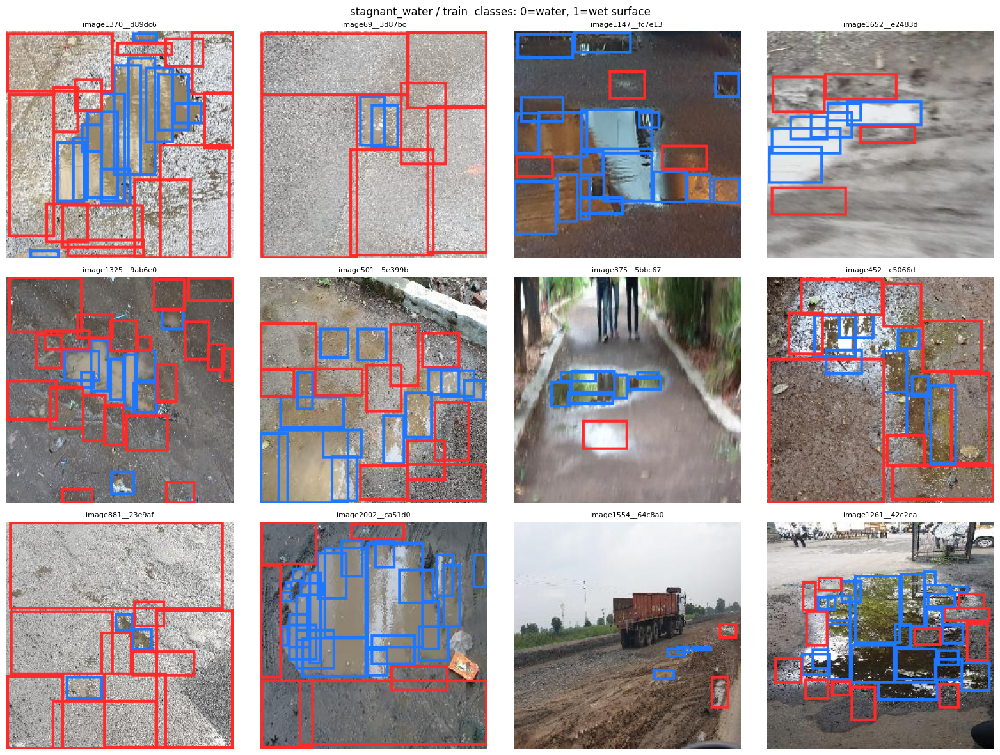

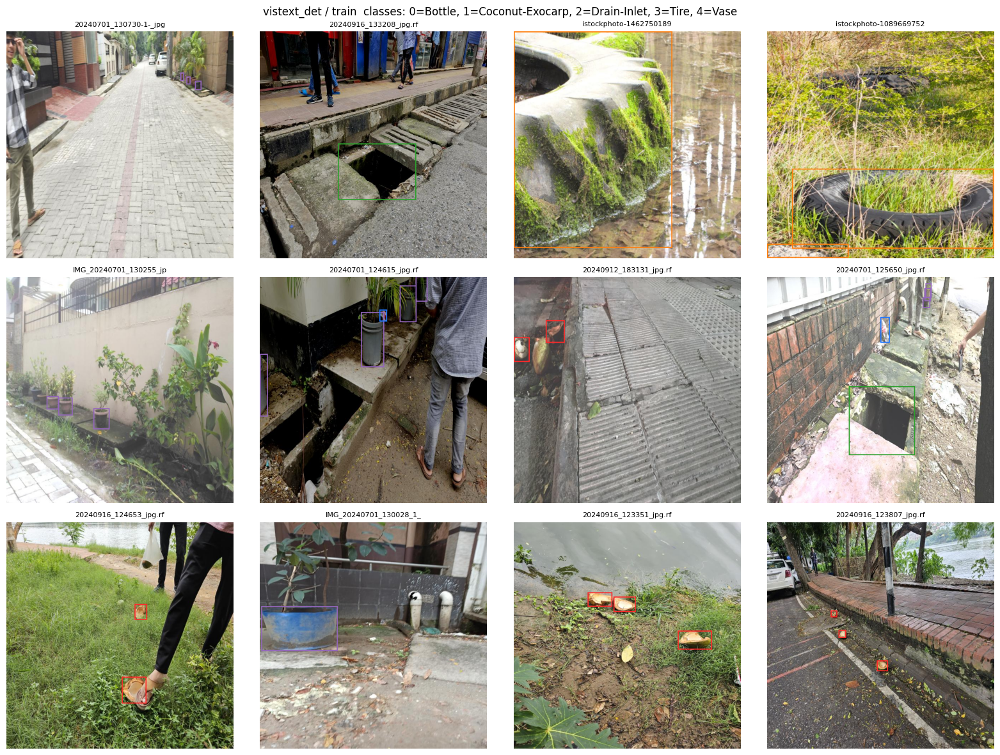

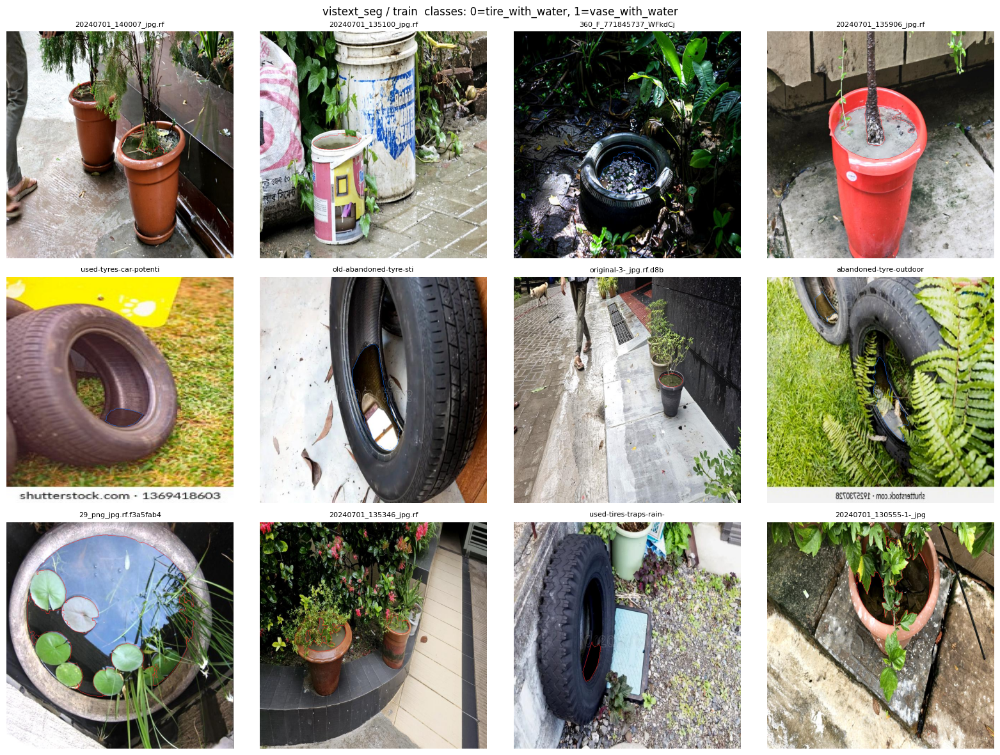

In [ ]:
COLORS = ['#1f77ff', '#ff2a2a', '#2ca02c', '#ff7f0e', '#9467bd']
def show(ds, kind, names, split='train', k=12, seed=1):
    files = sorted((OUT / ds / split / 'images').glob('*'))
    pick = random.Random(seed).sample(files, min(k, len(files)))
    cols = 4; rows = (len(pick) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    for ax, p in zip(np.array(axes).flatten(), pick):
        im = Image.open(p).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
        for c, v in read_labels(OUT / ds / split / 'labels' / (p.stem + '.txt')):
            col = COLORS[c % len(COLORS)]
            if kind == 'box' and len(v) == 4:
                cx, cy, w, h = v; d.rectangle([(cx - w/2)*W, (cy - h/2)*H, (cx + w/2)*W, (cy + h/2)*H], outline=col, width=3)
            elif len(v) >= 6:
                d.polygon([(v[i]*W, v[i+1]*H) for i in range(0, len(v), 2)], outline=col)
        ax.imshow(im); ax.set_title(p.stem[:22], fontsize=8); ax.axis('off')
    for ax in np.array(axes).flatten()[len(pick):]: ax.axis('off')
    plt.suptitle(f'{ds} / {split}  classes: ' + ', '.join(f'{i}={n}' for i, n in enumerate(names)))
    plt.tight_layout(); plt.show()

show('stagnant_water', 'box', SW_NAMES)
show('vistext_det', 'box', yaml_names(DET_ROOT))
show('vistext_seg', 'poly', yaml_names(SEG_ROOT))

**Review folder.** Images with no valid labels were NOT deleted; they were copied to `/content/clean/review/`. Look at them. If they are real background photos (no breeding site visible), they can be added back later as negative examples. If they clearly contain a tyre, vase, etc., they are missing labels and should stay out.

42 images in review


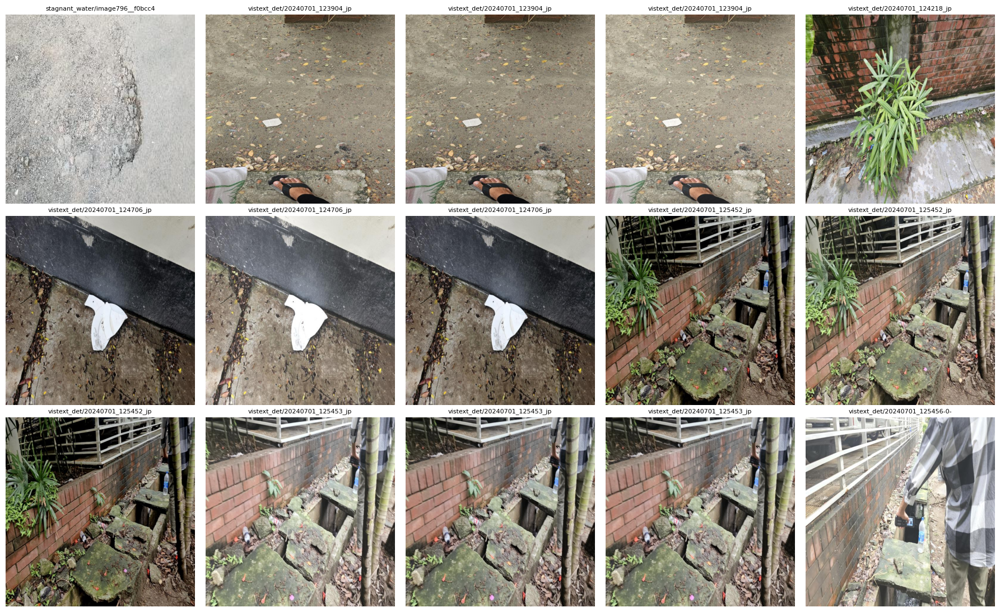

In [ ]:
rev = sorted((OUT / 'review').rglob('*.[jJ][pP]*[gG]'))
print(len(rev), 'images in review')
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for ax, p in zip(axes.flatten(), rev[:15]):
    ax.imshow(Image.open(p).convert('RGB')); ax.set_title(p.parent.name + '/' + p.stem[:18], fontsize=8); ax.axis('off')
for ax in axes.flatten()[len(rev[:15]):]: ax.axis('off')
plt.tight_layout(); plt.show()

## Step 7. Summary table and save to Drive

In [ ]:
rows = []
for ds in ['stagnant_water', 'vistext_det', 'vistext_seg']:
    dec = pd.read_csv(OUT / 'reports' / f'{ds}_decisions.csv')
    kept = (dec.action == 'kept').sum()
    rows.append(dict(dataset=ds, kept=kept, **dec[dec.action != 'kept'].reason.str.replace(r'_\(group.*|_in_.*', '', regex=True).value_counts().to_dict()))
display(pd.DataFrame(rows).fillna(0).astype({'kept': int}))

DRIVE_OUT.mkdir(parents=True, exist_ok=True)
archive = shutil.make_archive(str(DRIVE_OUT / 'nyahmuk_clean_v1'), 'zip', OUT)
print('Saved:', archive)

,dataset,kept,exact_duplicate,label_without_image,image_without_label,no_valid_annotations,leakage_copy,near_duplicate
0,stagnant_water,1807,167,1.0,1.0,1,0.0,0.0
1,vistext_det,4265,52,0.0,0.0,38,70.0,0.0
2,vistext_seg,303,4,0.0,0.0,3,19.0,2.0


Saved: /content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v1.zip


In [ ]:

from pathlib import Path
import zipfile
from collections import Counter

zip_path = Path(
    "/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v1.zip"
)

assert zip_path.exists(), f"ZIP not found: {zip_path}"

with zipfile.ZipFile(zip_path) as z:
    files = [f for f in z.namelist() if not f.endswith("/")]

    print("ZIP size (MB):", round(zip_path.stat().st_size / 1024**2, 2))
    print("Total files:", len(files))
    print("Integrity:", "PASS" if z.testzip() is None else "FAIL")

    counts = Counter()
    for f in files:
        parts = Path(f).parts
        if len(parts) >= 3 and parts[0] in {
            "stagnant_water", "vistext_det", "vistext_seg"
        }:
            if parts[-1].lower().endswith((".jpg", ".jpeg", ".png")):
                counts[(parts[0], parts[1])] += 1

    print("\nImage counts by dataset and split:")
    for key, value in sorted(counts.items()):
        print(f"{key[0]:16} {key[1]:8} {value}")

    print("\nSample files:")
    for f in files[:30]:
        print(f)

    print("\nAnnotation label counts:")
    for ds in ["stagnant_water", "vistext_det", "vistext_seg"]:
        labels = [
            f for f in files
            if f.startswith(ds + "/")
            and "/labels/" in f
            and f.endswith(".txt")
        ]
        print(ds, "label files:", len(labels))


ZIP size (MB): 470.65
Total files: 12804
Integrity: PASS

Image counts by dataset and split:
stagnant_water   test     180
stagnant_water   train    1445
stagnant_water   valid    182
vistext_det      test     182
vistext_det      train    3714
vistext_det      valid    369
vistext_seg      test     14
vistext_seg      train    260
vistext_seg      valid    29

Sample files:
stagnant_water/data.yaml
stagnant_water/train/images/image1901__a82c86.jpeg
stagnant_water/train/images/image1969__7865e3.jpeg
stagnant_water/train/images/image1379__adbf21.jpeg
stagnant_water/train/images/image1065__f3e4af.jpeg
stagnant_water/train/images/image1220__77f2ca.jpeg
stagnant_water/train/images/image942__2b923b.jpeg
stagnant_water/train/images/image573__821ca8.jpeg
stagnant_water/train/images/image1257__9396b2.jpeg
stagnant_water/train/images/image1023__df7af9.jpeg
stagnant_water/train/images/image768__fa1075.jpeg
stagnant_water/train/images/image77__13d69c.jpeg
stagnant_water/train/images/image385__2e1

##Visual Review & Duplicate Leakage Audit

Step 1 — Mount Drive and locate the ZIP

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v1.zip"
)

assert ZIP_PATH.exists(), (
    f"ZIP not found: {ZIP_PATH}\n"
    "Update ZIP_PATH to your actual Google Drive location."
)

print("ZIP:", ZIP_PATH)
print("Size (MB):", round(ZIP_PATH.stat().st_size / 1024**2, 2))

with zipfile.ZipFile(ZIP_PATH) as z:
    bad_file = z.testzip()
    print("ZIP integrity:", "PASS" if bad_file is None else f"FAIL: {bad_file}")

    names = z.namelist()
    review_images = [
        n for n in names
        if not n.endswith("/")
        and Path(n).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
        and "review" in n.lower()
    ]

    print("\nImage files in paths containing 'review':", len(review_images))
    for n in review_images[:60]:
        print(n)

    if len(review_images) > 60:
        print("... additional review images omitted")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP: /content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v1.zip
Size (MB): 470.65
ZIP integrity: PASS

Image files in paths containing 'review': 42
review/stagnant_water/image796__f0bcc4.jpeg
review/vistext_det/20240701_125459_jpg.rf.19566b74b6a47903f4950b9be6d0c3a9__1d85d2.jpg
review/vistext_det/20240912_182933_jpg.rf.f5ad9ff486883f6f4ce56c18bfa3d2e7__fcc974.jpg
review/vistext_det/20240701_135307_jpg.rf.aaaf97b27b08cd20b416ef1f99d05b89__d52464.jpg
review/vistext_det/20240701_124218_jpg.rf.350ea8e44d4b371f73de117e225d8248__522ad8.jpg
review/vistext_det/20240701_123904_jpg.rf.e221056a8a192a00565db5864bda8bd2__ff376e.jpg
review/vistext_det/20240701_123904_jpg.rf.35710cbce04c0f56a5dd714ab65d13b5__c0946e.jpg
review/vistext_det/IMG_20240701_124014_jpg.rf.7692113d8be553aff0c00f75e3f6d5f8__c638d5.jpg
review/vistext_det/20240916_125025_jpg.rf.66bd7fc63e071c77c5

Step 2 — Prepare the visual-inspection tools

In [ ]:

%pip -q install ImageHash pyyaml pandas matplotlib pillow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 8.0 MB/s eta 0:00:00


Review images found: 42


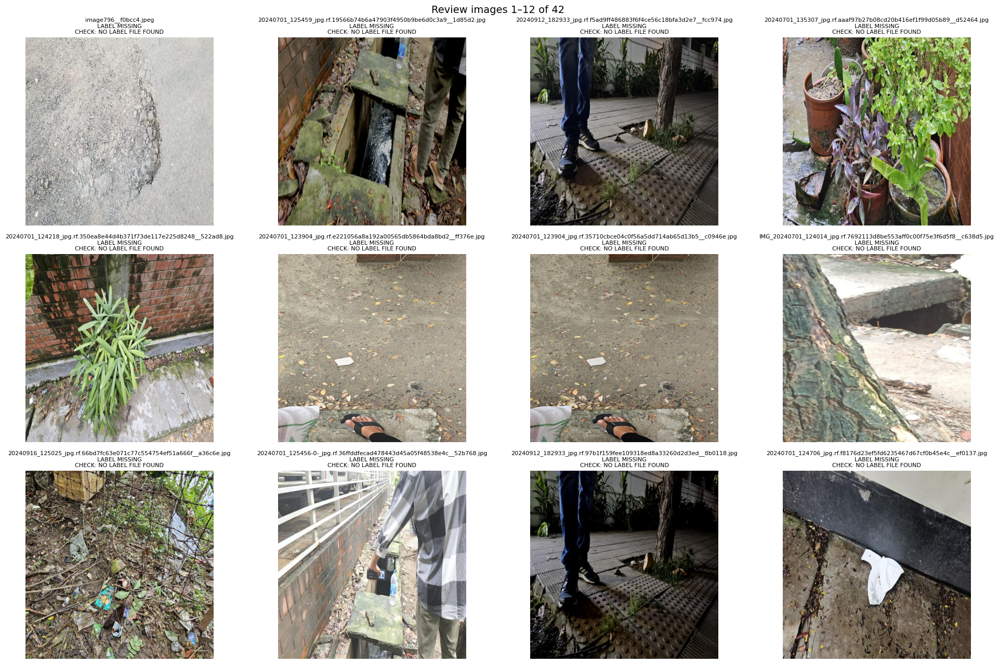

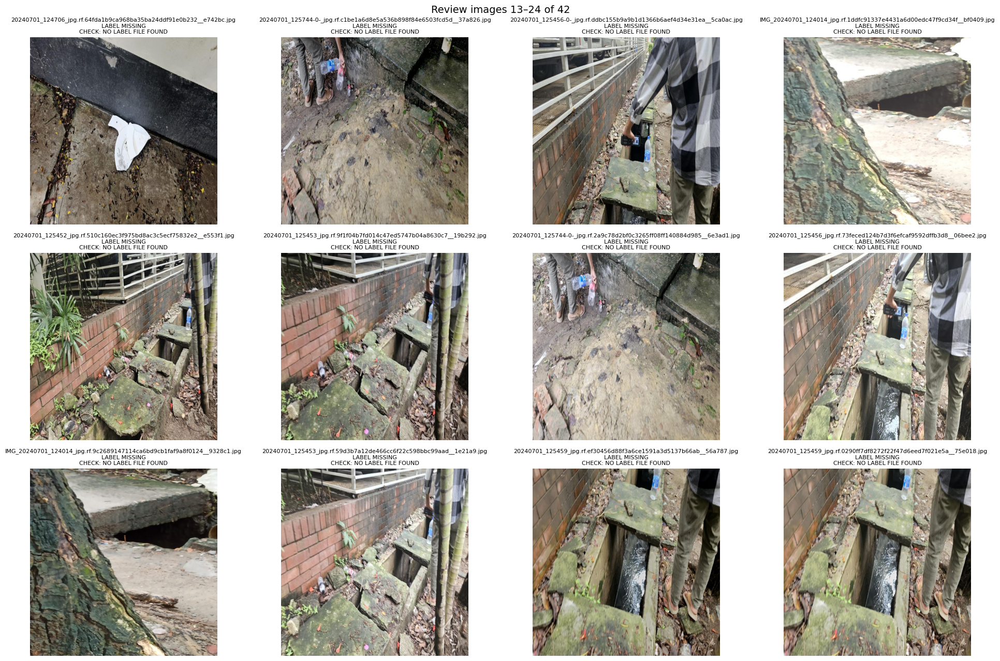

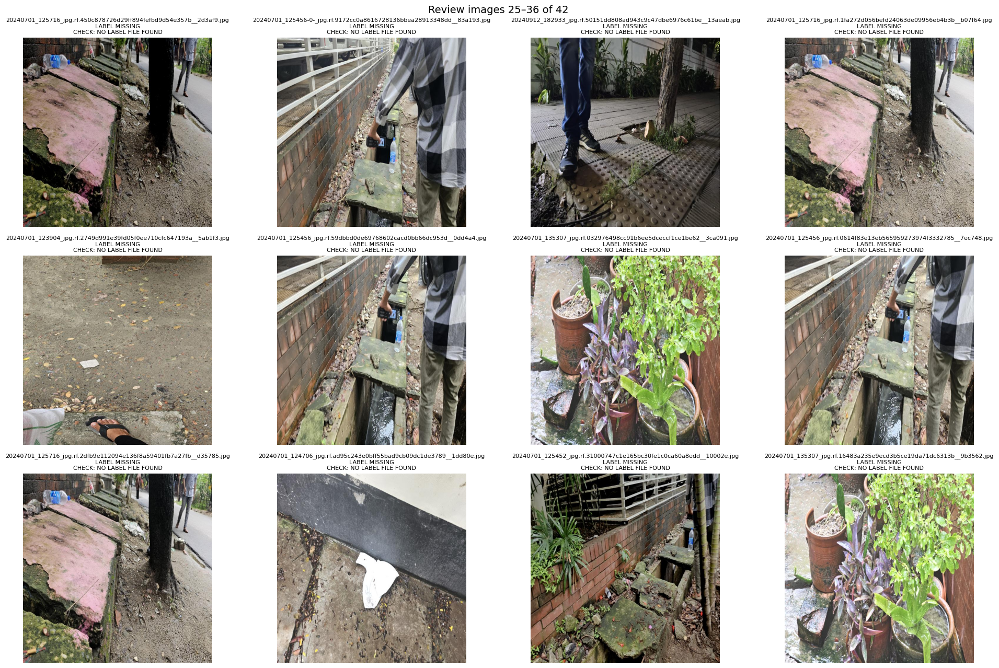

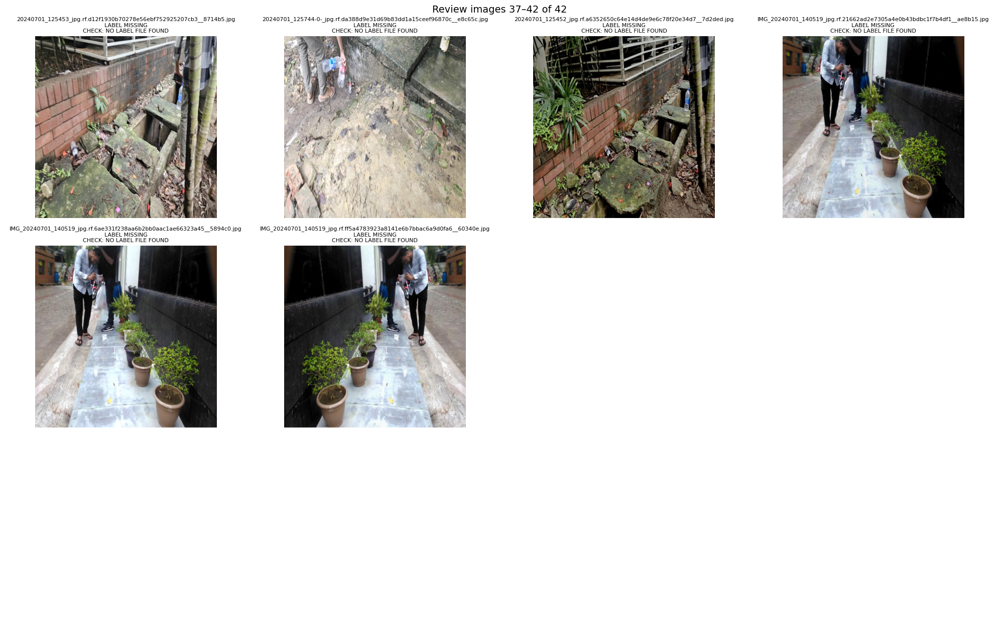

In [ ]:

import io
import math
import zipfile
from pathlib import PurePosixPath

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

with zipfile.ZipFile(ZIP_PATH) as z:
    all_names = [n for n in z.namelist() if not n.endswith("/")]
    review_names = [
        n for n in all_names
        if "review" in n.lower()
        and PurePosixPath(n).suffix.lower() in IMG_EXTS
    ]

    def find_label_path(image_path):
        p = PurePosixPath(image_path)
        candidates = []
        if "/images/" in image_path:
            candidates.append(image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt")
        candidates.append(str(p.with_suffix(".txt")))
        # Some review folders store labels beside images or in a sibling labels folder.
        for candidate in candidates:
            if candidate in all_names:
                return candidate
        return None

    def get_class_names(image_path):
        parts = PurePosixPath(image_path).parts
        dataset = parts[0] if parts else ""
        yaml_path = f"{dataset}/data.yaml"
        if yaml_path in all_names:
            try:
                config = yaml.safe_load(z.read(yaml_path))
                names = config.get("names", {})
                if isinstance(names, list):
                    return {i: str(v) for i, v in enumerate(names)}
                if isinstance(names, dict):
                    return {int(k): str(v) for k, v in names.items()}
            except Exception:
                pass
        return {}

    def render_review(image_path):
        raw = z.read(image_path)
        im = Image.open(io.BytesIO(raw)).convert("RGB")
        draw = ImageDraw.Draw(im)
        label_path = find_label_path(image_path)
        notes = []

        if label_path is None:
            notes.append("NO LABEL FILE FOUND")
        else:
            text = z.read(label_path).decode("utf-8", errors="replace")
            class_names = get_class_names(image_path)
            W, H = im.size
            for line_no, line in enumerate(text.splitlines(), 1):
                vals = line.split()
                if not vals:
                    continue
                try:
                    nums = [float(v) for v in vals]
                    if not all(np.isfinite(nums)):
                        notes.append(f"Line {line_no}: non-finite value")
                        continue
                    cls = int(nums[0])
                    label = class_names.get(cls, f"class_{cls}")

                    if len(nums) == 5:  # YOLO bounding box
                        _, xc, yc, bw, bh = nums
                        x1, y1 = (xc-bw/2)*W, (yc-bh/2)*H
                        x2, y2 = (xc+bw/2)*W, (yc+bh/2)*H
                        if not (0 <= x1 < x2 <= W and 0 <= y1 < y2 <= H):
                            notes.append(f"Line {line_no}: box outside image")
                        draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
                        draw.text((max(0, x1), max(0, y1-14)), label, fill="red",
                                  stroke_width=2, stroke_fill="white")

                    elif len(nums) >= 7 and len(nums[1:]) % 2 == 0:
                        # YOLO segmentation: class followed by normalized x,y pairs
                        coords = nums[1:]
                        pts = [(coords[i]*W, coords[i+1]*H)
                               for i in range(0, len(coords), 2)]
                        if len(pts) >= 3:
                            draw.line(pts + [pts[0]], fill="red", width=3)
                            draw.text(pts[0], label, fill="red",
                                      stroke_width=2, stroke_fill="white")
                    else:
                        notes.append(f"Line {line_no}: unexpected {len(nums)} values")
                except Exception as e:
                    notes.append(f"Line {line_no}: parse error ({e})")

        return im, label_path, notes

    print("Review images found:", len(review_names))
    if not review_names:
        print("No review images found inside this ZIP. Locate the external review folder.")
    else:
        for start in range(0, len(review_names), 12):
            batch = review_names[start:start+12]
            fig, axes = plt.subplots(3, 4, figsize=(20, 13))
            for ax in axes.flat:
                ax.axis("off")

            for ax, path in zip(axes.flat, batch):
                im, label_path, notes = render_review(path)
                ax.imshow(im)
                ax.set_title(
                    PurePosixPath(path).name
                    + ("\nLABEL MISSING" if label_path is None else "")
                    + ("\nCHECK: " + "; ".join(notes[:2]) if notes else ""),
                    fontsize=8
                )
                ax.axis("off")
            plt.suptitle(
                f"Review images {start+1}–{start+len(batch)} of {len(review_names)}",
                fontsize=14
            )
            plt.tight_layout()
            plt.show()


Step 3 — Audit exact and near-duplicate leakage

In [ ]:

import hashlib
import io
import zipfile
from pathlib import PurePosixPath
from collections import Counter

import imagehash
import pandas as pd
from PIL import Image

SPLITS = {"train", "valid", "test"}
PHASH_THRESHOLD = 6

def hamming(a, b):
    return (a ^ b).bit_count()

class BKNode:
    def __init__(self, value, index):
        self.value = value
        self.indices = [index]
        self.children = {}

class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value, index):
        if self.root is None:
            self.root = BKNode(value, index)
            return
        node = self.root
        while True:
            d = hamming(value, node.value)
            if d == 0:
                node.indices.append(index)
                return
            if d not in node.children:
                node.children[d] = BKNode(value, index)
                return
            node = node.children[d]

    def query(self, value, radius):
        results = []
        if self.root is None:
            return results
        stack = [self.root]
        while stack:
            node = stack.pop()
            d = hamming(value, node.value)
            if d <= radius:
                results.extend((i, d) for i in node.indices)
            lo, hi = d-radius, d+radius
            for edge, child in node.children.items():
                if lo <= edge <= hi:
                    stack.append(child)
        return results

def get_split_and_dataset(path):
    parts = PurePosixPath(path).parts
    if len(parts) >= 4 and parts[1] in SPLITS and parts[2] == "images":
        return parts[0], parts[1]
    return None, None

records = []
errors = []

with zipfile.ZipFile(ZIP_PATH) as z:
    image_paths = []
    for name in z.namelist():
        if name.endswith("/") or PurePosixPath(name).suffix.lower() not in IMG_EXTS:
            continue
        dataset, split = get_split_and_dataset(name)
        if dataset and split:
            image_paths.append(name)

    print("Images to hash:", len(image_paths))

    for i, path in enumerate(image_paths, 1):
        try:
            raw = z.read(path)
            sha = hashlib.sha256(raw).hexdigest()
            with Image.open(io.BytesIO(raw)) as im:
                im.load()
                ph = int(str(imagehash.phash(im.convert("RGB"))), 16)

            dataset, split = get_split_and_dataset(path)
            records.append({
                "path": path,
                "dataset": dataset,
                "split": split,
                "sha256": sha,
                "phash_int": ph,
                "phash_hex": f"{ph:016x}",
            })
        except Exception as e:
            errors.append({"path": path, "error": str(e)})

        if i % 500 == 0:
            print(f"Hashed {i}/{len(image_paths)}")

df = pd.DataFrame(records)
print("\nSuccessfully hashed:", len(df))
print("Unreadable/hash errors:", len(errors))
if errors:
    display(pd.DataFrame(errors).head(20))


Images to hash: 6375
Hashed 500/6375
Hashed 1000/6375
Hashed 1500/6375
Hashed 2000/6375
Hashed 2500/6375
Hashed 3000/6375
Hashed 3500/6375
Hashed 4000/6375
Hashed 4500/6375
Hashed 5000/6375
Hashed 5500/6375
Hashed 6000/6375

Successfully hashed: 6375
Unreadable/hash errors: 0


In [ ]:

from itertools import combinations
from pathlib import Path

# Exact duplicates: compare SHA-256 hashes.
exact_pairs = []
for sha, group in df.groupby("sha256"):
    rows = group.to_dict("records")
    if len(rows) > 1:
        for a, b in combinations(rows, 2):
            if a["split"] != b["split"]:
                exact_pairs.append({
                    "type": "EXACT",
                    "distance": 0,
                    "dataset_a": a["dataset"],
                    "split_a": a["split"],
                    "path_a": a["path"],
                    "dataset_b": b["dataset"],
                    "split_b": b["split"],
                    "path_b": b["path"],
                })

# Near-duplicates across different splits.
tree = BKTree()
near_pairs = set()
near_records = []

for idx, row in df.iterrows():
    for other_idx, distance in tree.query(row["phash_int"], PHASH_THRESHOLD):
        other = df.iloc[other_idx]

        if row["split"] == other["split"]:
            continue

        pair = tuple(sorted((int(idx), int(other_idx))))
        if pair in near_pairs:
            continue
        near_pairs.add(pair)

        is_exact = row["sha256"] == other["sha256"]
        near_records.append({
            "type": "EXACT" if is_exact else "NEAR_DUPLICATE_CANDIDATE",
            "distance": distance,
            "dataset_a": other["dataset"],
            "split_a": other["split"],
            "path_a": other["path"],
            "dataset_b": row["dataset"],
            "split_b": row["split"],
            "path_b": row["path"],
        })

    tree.add(row["phash_int"], int(idx))

pairs_df = pd.DataFrame(near_records)

print("=== CROSS-SPLIT DUPLICATE AUDIT ===")
print("Images checked:", len(df))
print("Unreadable images:", len(errors))
print("Exact duplicate cross-split pairs:", len(exact_pairs))
print("Near/exact candidate pairs at pHash distance <=", PHASH_THRESHOLD,
      ":", len(pairs_df))

if not pairs_df.empty:
    print("\nPairs by type:")
    print(pairs_df["type"].value_counts().to_string())

    print("\nPairs by split combination:")
    pairs_df["split_pair"] = pairs_df.apply(
        lambda r: " ↔ ".join(sorted([r["split_a"], r["split_b"]])), axis=1
    )
    print(pairs_df["split_pair"].value_counts().to_string())

    print("\nFirst 30 flagged pairs:")
    display(pairs_df.head(30))
else:
    print("No cross-split candidate pairs found at this threshold.")

# Save reports to Drive.
REPORT_DIR = Path("/content/drive/MyDrive/NyahMuk/audit_reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df.drop(columns=["phash_int"]).to_csv(
    REPORT_DIR / "image_hash_manifest.csv", index=False
)
pairs_df.to_csv(REPORT_DIR / "cross_split_duplicate_candidates.csv", index=False)
pd.DataFrame(exact_pairs).to_csv(
    REPORT_DIR / "exact_cross_split_duplicates.csv", index=False
)
pd.DataFrame(errors).to_csv(
    REPORT_DIR / "image_hash_errors.csv", index=False
)

print("\nReports saved to:", REPORT_DIR)
print(" - image_hash_manifest.csv")
print(" - cross_split_duplicate_candidates.csv")
print(" - exact_cross_split_duplicates.csv")
print(" - image_hash_errors.csv")


=== CROSS-SPLIT DUPLICATE AUDIT ===
Images checked: 6375
Unreadable images: 0
Exact duplicate cross-split pairs: 1
Near/exact candidate pairs at pHash distance <= 6 : 97

Pairs by type:
type
NEAR_DUPLICATE_CANDIDATE    96
EXACT                        1

Pairs by split combination:
split_pair
train ↔ valid    68
test ↔ train     25
test ↔ valid      4

First 30 flagged pairs:


,type,distance,dataset_a,split_a,path_a,dataset_b,split_b,path_b,split_pair
0,NEAR_DUPLICATE_CANDIDATE,6,vistext_det,train,vistext_det/train/images/20240701_125336_jpg.r...,vistext_det,valid,vistext_det/valid/images/20240701_125336-0-_jp...,train ↔ valid
1,NEAR_DUPLICATE_CANDIDATE,6,vistext_det,train,vistext_det/train/images/20240701_125336_jpg.r...,vistext_det,valid,vistext_det/valid/images/20240701_125336-0-_jp...,train ↔ valid
2,NEAR_DUPLICATE_CANDIDATE,6,vistext_det,train,vistext_det/train/images/1726484414311_jpg.rf....,vistext_det,valid,vistext_det/valid/images/1726484414273_jpg.rf....,train ↔ valid
3,NEAR_DUPLICATE_CANDIDATE,6,vistext_det,train,vistext_det/train/images/1726484414311_jpg.rf....,vistext_det,valid,vistext_det/valid/images/1726484414273_jpg.rf....,train ↔ valid
4,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,valid,vistext_det/valid/images/360_F_597147643_dwfK1...,vistext_seg,train,vistext_seg/train/images/close-up-abandoned-ti...,train ↔ valid
5,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,test,vistext_det/test/images/20240701_140518_jpg.rf...,vistext_seg,train,vistext_seg/train/images/20240701_140518_jpg.r...,test ↔ train
6,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,test,vistext_det/test/images/20240701_140518_jpg.rf...,vistext_seg,train,vistext_seg/train/images/20240701_140518_jpg.r...,test ↔ train
7,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,valid,vistext_det/valid/images/idle-used-tire-open-a...,vistext_seg,train,vistext_seg/train/images/idle-used-tire-open-a...,train ↔ valid
8,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,valid,vistext_det/valid/images/used-tyres-potentiall...,vistext_seg,train,vistext_seg/train/images/used-tyres-potentiall...,train ↔ valid
9,NEAR_DUPLICATE_CANDIDATE,0,vistext_det,valid,vistext_det/valid/images/20240701_135306_jpg.r...,vistext_seg,train,vistext_seg/train/images/20240701_135306_jpg.r...,train ↔ valid



Reports saved to: /content/drive/MyDrive/NyahMuk/audit_reports
 - image_hash_manifest.csv
 - cross_split_duplicate_candidates.csv
 - exact_cross_split_duplicates.csv
 - image_hash_errors.csv


Step 4 — Visually confirm flagged duplicate pairs

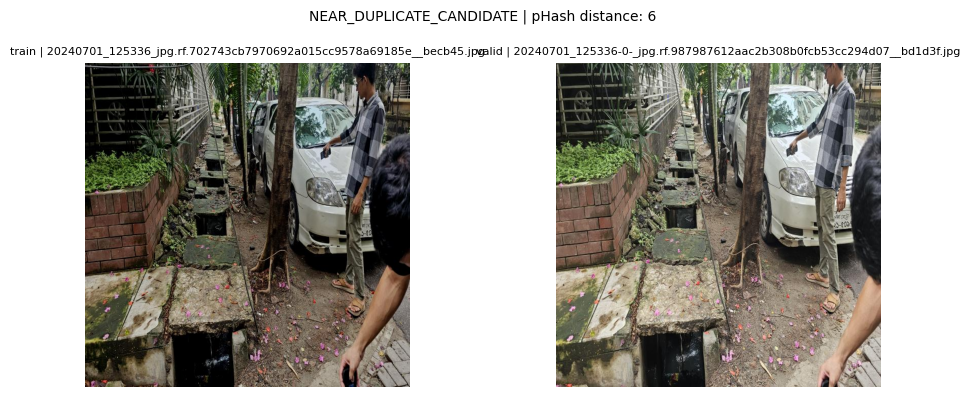

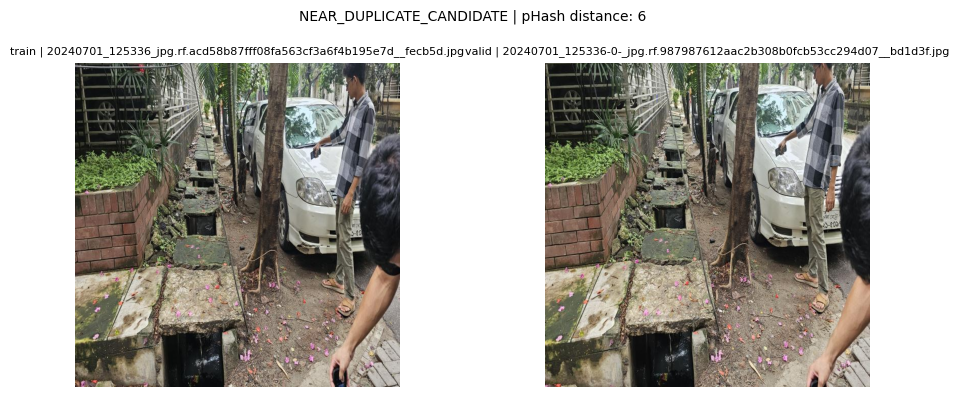

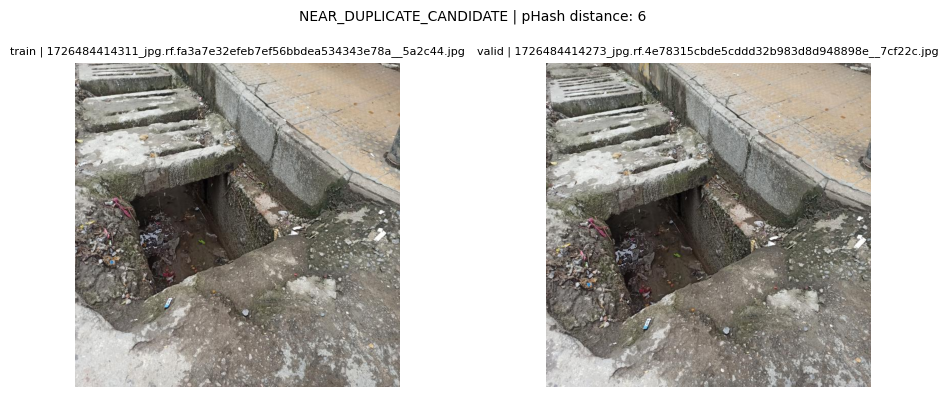

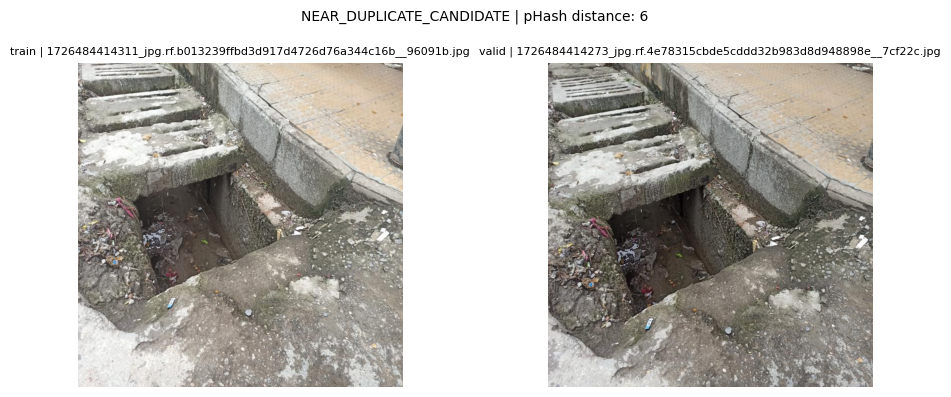

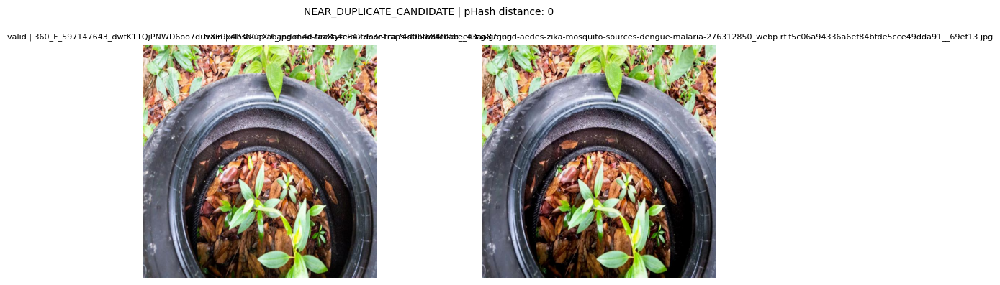

...

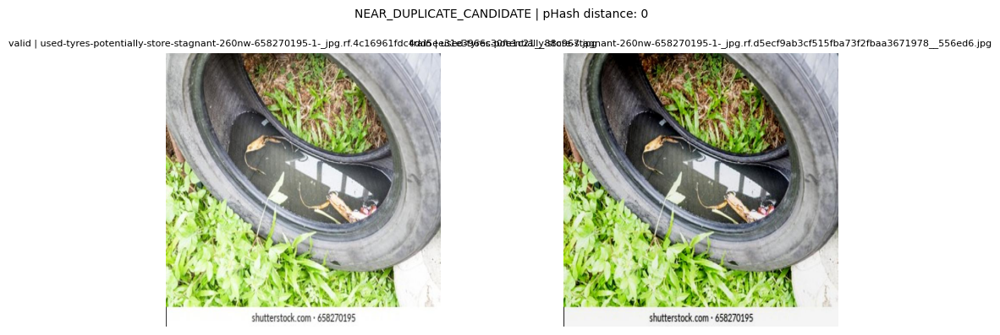

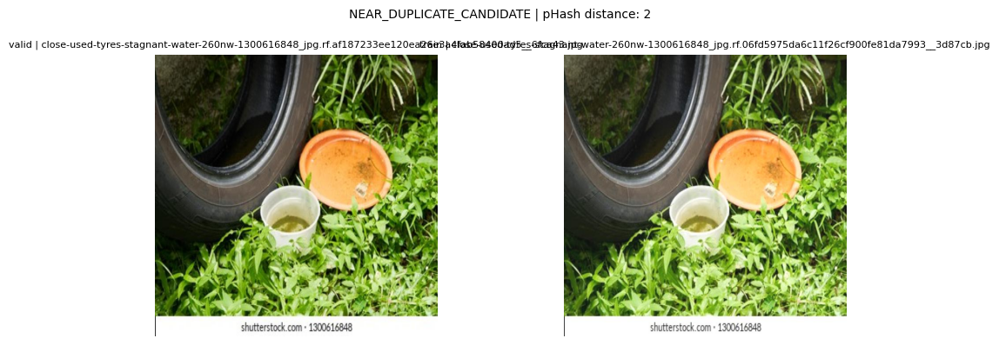

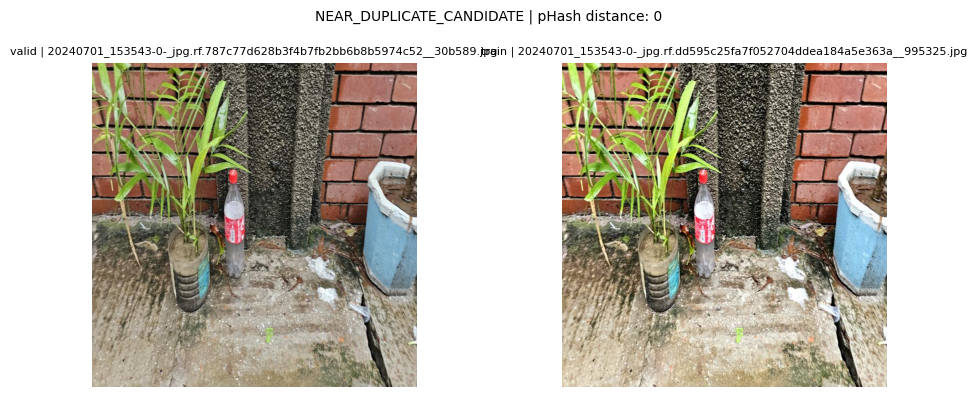

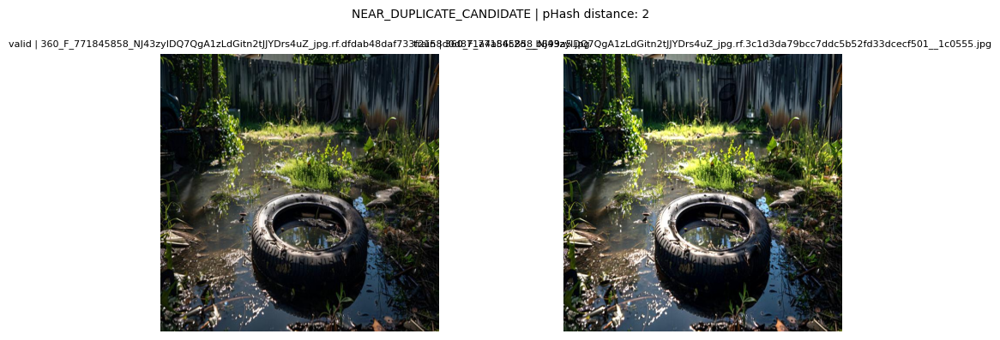

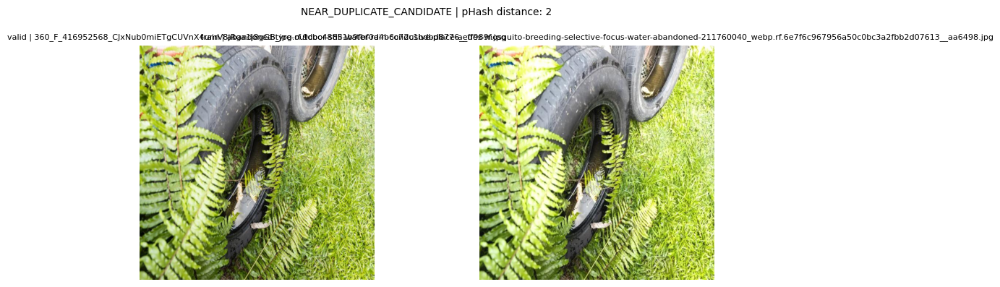

In [ ]:

import matplotlib.pyplot as plt
import io
import zipfile
from PIL import Image
from pathlib import PurePosixPath

with zipfile.ZipFile(ZIP_PATH) as z:
    flagged = pairs_df.head(20)

    if flagged.empty:
        print("No cross-split candidate pairs to display.")
    else:
        for _, pair in flagged.iterrows():
            fig, axes = plt.subplots(1, 2, figsize=(10, 4))

            for ax, path_col, split_col in [
                (axes[0], "path_a", "split_a"),
                (axes[1], "path_b", "split_b"),
            ]:
                path = pair[path_col]
                im = Image.open(io.BytesIO(z.read(path))).convert("RGB")
                ax.imshow(im)
                ax.set_title(
                    f"{pair[split_col]} | {PurePosixPath(path).name}",
                    fontsize=8
                )
                ax.axis("off")

            fig.suptitle(
                f"{pair['type']} | pHash distance: {pair['distance']}",
                fontsize=10
            )
            plt.tight_layout()
            plt.show()


##FIX CODE

In [4]:
import zipfile, shutil, pandas as pd
from pathlib import Path

CLEAN = Path('/content/clean')
if not (CLEAN / 'vistext_det').exists():
    zipfile.ZipFile('/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v1.zip').extractall(CLEAN)

c = pd.read_csv('/content/drive/MyDrive/NyahMuk/audit_reports/cross_split_duplicate_candidates.csv')
dd = c[(c.dataset_a == 'vistext_det') & (c.dataset_b == 'vistext_det')]

removed = set()
for _, r in dd.iterrows():
    for p, s in [(r.path_a, r.split_a), (r.path_b, r.split_b)]:
        if s == 'train':
            img = CLEAN / p
            lbl = (CLEAN / p.replace('/images/', '/labels/')).with_suffix('.txt')
            for f in (img, lbl):
                if f.exists(): f.unlink()
            removed.add(p)
print('removed train images:', len(removed))   # expect 4

out = shutil.make_archive('/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v2', 'zip', CLEAN)
print('Saved:', out)

removed train images: 4
Saved: /content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v2.zip
